### Task 0: Descriptive analysis
For each of the three files, before you tidy, join, or reshape a single
one of them: load it and report its shape (rows × columns); show the first few rows; and say, with
justification, whether it is tidy – citing specifically which of the three rules it does or doesn’t satisfy.
Then produce at least one exploratory visualization of the data in its raw form.

The rules for data to be tidy:

Rule 1: Each variable must have its own column.

Rule 2: Each observation must have its own row. 

Rule 3: Each value must have its own cell. 

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker
from pathlib import Path

In [14]:
LOCAL_RAW = Path.cwd().resolve().parents[0]
OUT = Path.cwd().resolve().parents[0] / "output"
OUT.mkdir(exist_ok=True)


In [15]:
#Read files
orders = pd.read_csv(LOCAL_RAW/"data/orders-1.csv")
revenue = pd.read_csv(LOCAL_RAW/"data/company_quarterly_revenue_raw.csv")
shipments = pd.read_csv(LOCAL_RAW/"data/shipments.csv")

In [ ]:
#Print shapes
print(f'Shape of orders:{orders.shape}\n')
print(f'Shape of revenue:{revenue.shape}\n')
print(f'Shape of shipments:{shipments.shape}\n')

Shape of orders:,(20, 5)

Shape of revenue,(5, 13)

Shape of shipments,(35, 2)



**First few rows of the dataset and the Justication:**

In [17]:
#First few rows of orders:
orders.head()

,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3


Data is 'maybe' tidy:

Each cell does not hold a single value debatably. The year and quarter value can be treated as one then it doesn't violate Rule 3, however if problem statement needs year and quarter seprated, then it would be a violation of Rule 3. 

Every column represents a distinct, unique variable. 

Every single row represents one distinct observational unit.


In [18]:
#First few rows of revenue:
revenue.head()

,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


Data is not tidy

Each variable does not have its own column. 
The column headers  are actually values of an underlying Time variable, rather than being variable names themselves. Furthermore, the core variable being measured Revenue does not have its own dedicated column; its values are scattered across twelve different columns.

Each observation does not have its own row.
A single observation in this context is the revenue generated by a specific company during a specific quarter. Instead of one observation per row, each row contains twelve separate observations horizontally grouped by company.

Each value does not have its own cell
The data currently acting as column headers (2023-Q1) bundles two distinct pieces of information together: the Year (2023) and the Quarter (Q1). [Assuming problem statement needs Year and quarter info seperated]



In [19]:
#First few rows of shipments:
shipments.head()

,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1


Data is tidy:

Each cell holds a single value.

Every column represents a distinct, unique variable. 

Every single row represents one distinct observational unit.


**Exploratory visualization**

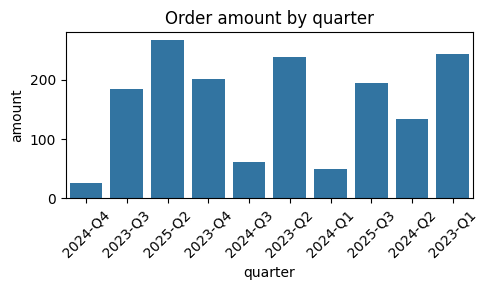

In [22]:
#Exploratory visualization in raw form for orders

#Order amount by quarter (raw order rows, summed per quarter)
plt.figure(figsize=(5, 3))
sns.barplot(data=orders, x="quarter", y="amount", estimator=sum, errorbar=None)
plt.title("Order amount by quarter")
plt.xlabel("quarter")
plt.ylabel("amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

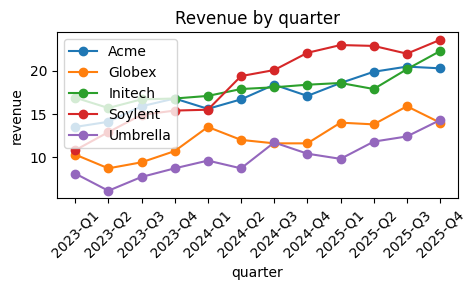

In [21]:
#Exploratory visualization in raw form for revenue

#Revenue by quarter (raw wide table: one line per company row)
plt.figure(figsize=(5,3))
for _, row in revenue.iterrows():
    plt.plot(revenue.columns[1:], row[1:], marker="o", label=row["company"])
plt.title("Revenue by quarter")
plt.xlabel("quarter")
plt.ylabel("revenue")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

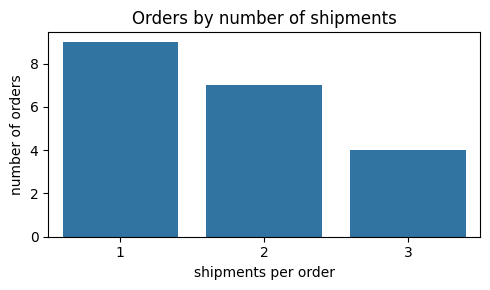

In [23]:
#Exploratory visualization in raw form for shipment

#Orders by number of shipments (count shipment rows per order_id)
plt.figure(figsize=(5, 3))
sns.countplot(x=shipments["order_id"].value_counts())
plt.title("Orders by number of shipments")
plt.xlabel("shipments per order")
plt.ylabel("number of orders")
plt.tight_layout()
plt.show()

### Task 1: Revenue table
Check revenue table, is it long or wide: If it is wide reshape it into one
row per (company, quarter) observation. Name, specifically, which rule of tidy data the raw file was
violating – “it was wide” is not a sufficient answer.

In [25]:
#Display revenue table:
revenue.head()


,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


Revenue table is wide

Rules violated all 3: 
Each variable does not have its own column. 
The column headers  are actually values of an underlying Time variable, rather than being variable names themselves. Furthermore, the core variable being measured Revenue does not have its own dedicated column; its values are scattered across twelve different columns.

Each observation does not have its own row.
A single observation in this context is the revenue generated by a specific company during a specific quarter. Instead of one observation per row, each row contains twelve separate observations horizontally grouped by company.

Each value does not have its own cell
The data currently acting as column headers (2023-Q1) bundles two distinct pieces of information together: the Year (2023) and the Quarter (Q1). [Assuming the problem statement needs year and quarters seperated]



In [26]:
#Since revenue table is wide - Reshaping revenue table:
df_revenue_long = pd.melt(
    revenue, 
    id_vars=['company'],                # Columns to keep as identifiers
    value_vars=['2023-Q1', '2023-Q2',	'2023-Q3',	'2023-Q4',	'2024-Q1',	'2024-Q2',	'2024-Q3'	,'2024-Q4'	,'2025-Q1',	'2025-Q2',	'2025-Q3'	,'2025-Q4'],  # Columns to unpivot (optional, defaults to all others)
    var_name='quarter',                  # Name for the new category column
    value_name='revenue'                   # Name for the new numerical values column
)

In [27]:
df_revenue_long.head()

,company,quarter,revenue
0,Acme,2023-Q1,13.5
1,Globex,2023-Q1,10.3
2,Initech,2023-Q1,16.9
3,Soylent,2023-Q1,10.8
4,Umbrella,2023-Q1,8.1


In [28]:
#Splitting quarter:
df_revenue_long[['year', 'quarter']] = df_revenue_long['quarter'].str.split('-', expand=True)
df_revenue_long.head()

,company,quarter,revenue,year
0,Acme,Q1,13.5,2023
1,Globex,Q1,10.3,2023
2,Initech,Q1,16.9,2023
3,Soylent,Q1,10.8,2023
4,Umbrella,Q1,8.1,2023


Cleaning Order table - split year and quarter

In [30]:
orders.head()

,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3


In [31]:
#Split quarter
orders[['year', 'quarter']] = orders['quarter'].str.split('-', expand=True) 
orders.head()

,order_id,customer_id,amount,company,quarter,year
0,O1000,C106,26,Umbrella,Q4,2024
1,O1001,C105,48,Umbrella,Q3,2023
2,O1002,C103,155,Globex,Q2,2025
3,O1003,C100,38,Acme,Q4,2023
4,O1004,C103,136,Globex,Q3,2023


### Task 2: Duplicate keys?
confirm whether order id is actually unique in orders.csv and in shipments.csv, and say what that tells you about the cardinality of the join you’re about to do.

In [37]:
orders.head(10)

,order_id,customer_id,amount,company,quarter,year
0,O1000,C106,26,Umbrella,Q4,2024
1,O1001,C105,48,Umbrella,Q3,2023
2,O1002,C103,155,Globex,Q2,2025
3,O1003,C100,38,Acme,Q4,2023
4,O1004,C103,136,Globex,Q3,2023
5,O1005,C107,144,Soylent,Q4,2023
6,O1006,C101,62,Acme,Q3,2024
7,O1007,C103,64,Globex,Q2,2025
8,O1008,C106,48,Umbrella,Q2,2025
9,O1009,C105,122,Umbrella,Q2,2023


In [34]:
#Checking if orderid is unique in orders table
print(orders['order_id'].duplicated().any())
print(orders['order_id'].nunique()) #number of rows matches no. of unique values

False
20


order_id is unique in orders table

In [38]:
shipments.head(10)

,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1
5,O1003,O1003-2
6,O1004,O1004-1
7,O1004,O1004-2
8,O1004,O1004-3
9,O1005,O1005-1


In [39]:
#Checking if orderid is unique in shipments table
print(shipments['order_id'].duplicated().any())
print(shipments['order_id'].nunique()) #no. of rows are greater than no. of unique value

True
20


order_id is not unique in shipments table

It seems orders and shipments tables have 1:many relationship as for each multiple order_id there are multiple order_ids available in shipments table

### Task 3: Join orders and shipments correctly.
Compute the mean amount per customer: (a)
directly on the joined table, and (b) on orders alone. If the two numbers disagree, say which one
is correct and why.

In [45]:
#performing join of orders and shipments tables
order_shipment_join = pd.merge(orders,shipments,on='order_id',how='left')
mean_joined = order_shipment_join.groupby('customer_id')['amount'].mean() #(a) mean on joined
mean_orders = orders.groupby('customer_id')['amount'].mean() #(b) mean on orders alone
print("\nmean of joined table")
print(mean_joined)
print("\nmean of orders table alone")
print(mean_orders)
print("\n difference in means:")
print(mean_joined - mean_orders)



mean of joined table
customer_id
C100     38.000
C101     62.000
C102    105.000
C103    112.375
C104     33.000
C105     67.625
C106     62.250
C107    106.000
Name: amount, dtype: float64

mean of orders table alone
customer_id
C100     38.00
C101     62.00
C102    105.00
C103    111.60
C104     33.00
C105     67.25
C106     59.50
C107     96.50
Name: amount, dtype: float64

 difference in means:
customer_id
C100    0.000
C101    0.000
C102    0.000
C103    0.775
C104    0.000
C105    0.375
C106    2.750
C107    9.500
Name: amount, dtype: float64


Justification: 
As can be seen from the differences in means printed above, means are different for 4 customer_id C103, C105, C106, C107. 
The joined table takes the mean on the join of order and shipement tables that has 35 rows, compared to 20 rows in orders table. This weights orders against the number of shipments rather than counting it just once. So, the means would not match anytime an order has more than one shipments

### Task 4: Produce one analysis-ready table
Combine your tidy revenue table and your correctly-
joined order data into a single table someone else could pick up and start analyzing immediately,
i.e. sensible column names, one row per observation, no leftover index artifacts.

In [49]:
df_revenue_long.head()

,company,quarter,revenue,year
0,Acme,Q1,13.5,2023
1,Globex,Q1,10.3,2023
2,Initech,Q1,16.9,2023
3,Soylent,Q1,10.8,2023
4,Umbrella,Q1,8.1,2023


In [50]:
order_shipment_join.head()

,order_id,customer_id,amount,company,quarter,year,tracking
0,O1000,C106,26,Umbrella,Q4,2024,O1000-1
1,O1001,C105,48,Umbrella,Q3,2023,O1001-1
2,O1001,C105,48,Umbrella,Q3,2023,O1001-2
3,O1002,C103,155,Globex,Q2,2025,O1002-1
4,O1003,C100,38,Acme,Q4,2023,O1003-1


In [57]:
#renaming tracking to tracking id:
order_shipment_join = order_shipment_join.rename(columns = {"tracking": "tracking_id"})

#removing whitespaces:
# Identify all object/string columns
string_cols = order_shipment_join.select_dtypes(include=['object']).columns

# Strip whitespace from those columns
order_shipment_join[string_cols] = order_shipment_join[string_cols].apply(lambda x: x.str.strip())

In [58]:
#Join
final_table = pd.merge(
    order_shipment_join, 
    df_revenue_long, 
    on=['company', 'year','quarter'], 
    how='left'
)

In [59]:
final_table.shape

(35, 8)

In [60]:
final_table.head()

,order_id,customer_id,amount,company,quarter,year,tracking_id,revenue
0,O1000,C106,26,Umbrella,Q4,2024,O1000-1,10.4
1,O1001,C105,48,Umbrella,Q3,2023,O1001-1,7.7
2,O1001,C105,48,Umbrella,Q3,2023,O1001-2,7.7
3,O1002,C103,155,Globex,Q2,2025,O1002-1,13.8
4,O1003,C100,38,Acme,Q4,2023,O1003-1,16.8


In [63]:
#exporting final table to csv
final_table.to_csv(LOCAL_RAW/"output"/"final_table.csv")

### Task 5: Visualization
Produce one chart from your final table that would not have been straight-
forward to make before you tidied and joined the data. Put it side by side with your Step 0 chart
of the raw data and say, specifically, what got easier.

***Chart using tidied and cleaned vs raw***

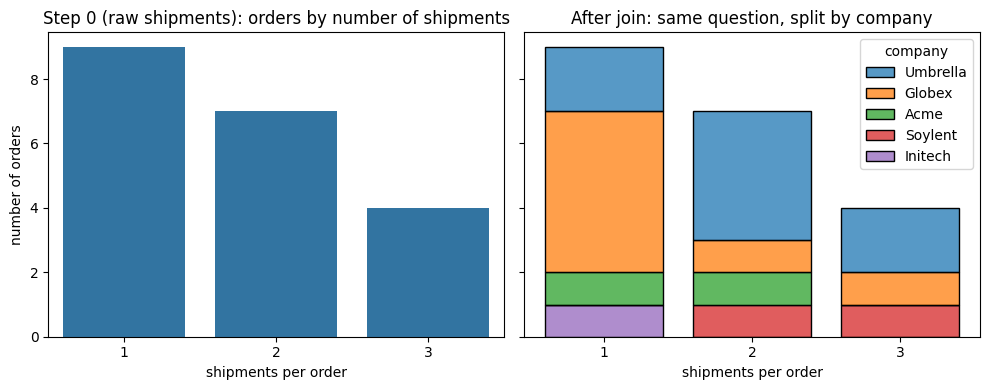

In [62]:
# One row per order (the joined table has one row per shipment)
per_order = (final_table.groupby("order_id")
               .agg(company=("company", "first"),
                    amount=("amount", "first"),
                    n_shipments=("tracking_id", "nunique"))
               .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

# Left: Step 0, raw shipments only
sns.countplot(x=shipments["order_id"].value_counts(), ax=axes[0])
axes[0].set_title("Step 0 (raw shipments): orders by number of shipments")
axes[0].set_xlabel("shipments per order")
axes[0].set_ylabel("number of orders")

# Right: same question after the join, now split by company
sns.histplot(data=per_order, x="n_shipments", hue="company", multiple="stack",
             discrete=True, shrink=0.8, ax=axes[1])
axes[1].set_xticks([1, 2, 3])
axes[1].set_title("After join: same question, split by company")
axes[1].set_xlabel("shipments per order")

plt.tight_layout()
plt.show()

Before joining and deriving the final table, the info was spread across 3 different files. For example in the plots generated above, shipments dataset could only display the number of orders as it has just the order_id and tracking, however, upon join it was possible to identify the distribution of number of orders by company providing additional insight.